## Introduction to generative AI 
#### HW02: Generating samples from a mixture of Gaussians

Name (member 1): Eloísa Denia García

Name (member 2): Matin Esmaeilzadeh

Name (member 3):

Date: 19/09/2026

In [2]:
import numpy as np
import matplotlib.pyplot as plt

from tools.gmm import (
    gmm_pdf, 
    gmm_score,
    gmm_sample, 
    gmm_plot_sample_with_density, 
    sample_langevin,
)

%load_ext autoreload
%autoreload 2

## Gaussian mixture models (GMM)
Consider a mixture of Gaussians in $D$ dimensions
$$
p\left(\mathbf{x}; \left\{\pi_k, \boldsymbol{\mu}_k, \boldsymbol{\Sigma}_k \right\}_{k=1}^{K} \right) = \sum_{k=1}^{K} \pi_k \, \mathcal{N}(\mathbf{x}; \boldsymbol{\mu}_k, \boldsymbol{\Sigma}_k), \qquad \mathbf{x} \in \mathbb{R}^{D}, 
$$
with $\boldsymbol{\pi} = \left(\pi_1,\ldots,\pi_K\right)^{\text{T}}  \in \Delta^{K-1}$, the $K-1$ probability simplex.

The mean and the covariance matrix of the $k$-th Gaussian in the mixture, with $k \in \left\{1, \ldots, K \right\}$, are $\boldsymbol{\mu}_k \in \mathbb{R}^{D}$ and $\boldsymbol{\Sigma}_k \in \mathbb{R}^{D \times D}$, respectively.

1. Write the Python function `gmm_pdf` to compute the pdf of a GMM
2.  **[TO DO]** Write the Python function `gmm_score` whose output is an iid sample of size $N$ from this distribution using 
    * $N$ samples from the categorical distribution with parameter $\boldsymbol{\pi}$.
    * $N$ samples from a standard normal distribution in $D$ dimensions.
    * The Cholesky decomposition of $\boldsymbol{\Sigma}_k$.

For a mixure of $K=3$ Gaussians in $D=2$ dimensions with 
$$
\begin{eqnarray}
\boldsymbol{\pi}   & = & \left(\frac{1}{3}, \frac{1}{3} , \frac{1}{3} \right)^{\text{T}}  \in \Delta^2. \\
\boldsymbol{\mu}_1 & = & \left(0,\, 10 \right)^{\text{T}}, \\ 
\boldsymbol{\mu}_2 & = & \left(-5\sqrt{3},\, -5 \right)^{\text{T}},  \\ 
\boldsymbol{\mu}_3 & = & \left(5\sqrt{3},\, -5 \right)^{\text{T}}, \\
\boldsymbol{\Sigma}_k & = & \mathcal{I} \in \mathbb{R^2},  \qquad \text{ for all } k = 1, \ldots, K. 
\end{eqnarray}
$$

1. Generate $\mathcal{D} = \left\{\mathbf{x}_n \right\}_{n=1}^N$, an iid sample of size $N =100$, with $\mathbf{x}_n \sim p\left(\mathbf{x}; \left\{\pi_k, \boldsymbol{\mu}_k, \boldsymbol{\Sigma}_k \right\}_{k=1}^{K} \right)$.
2. Generate a scatterplot for the generated samples. 
3. On the same plot, draw contours of equal probability density and represent the height of the pdf as a heatmap.  

In [3]:
# Try examples in gmm_sample
weights = [0.3, 0.7]
means = np.array([[0.0, 0.0], [5.0, 5.0]])
covariances = np.array([
        [[1.0, 0.0], [0.0, 1.0]],
        [[1.5, 0.2], [0.2, 1.5]],
        ])
samples = gmm_sample(
        n_samples=1000,
        weights=weights,
        means=means,
        covariances=covariances,
        random_state=42,
        )
print(samples.shape) #(1000, 2)

# Single-component "mixture" (reduces to a single normal)
samples = gmm_sample(
        n_samples=500,
        weights=[1.0],
        means=np.zeros((1, 3)),
        covariances=np.eye(3)[None, :, :],
        random_state=0,
        )
samples.shape #(500, 3)

(1000, 2)


(500, 3)

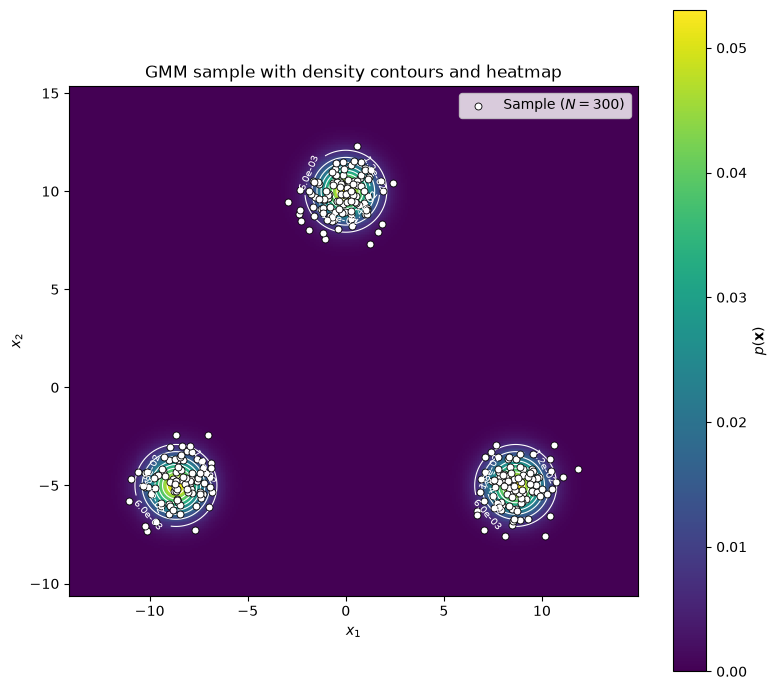

In [4]:
# ----------------------------------------------------------------------
# Generate D = {x_n}_{n=1}^N, an iid sample of size N = 100, from the GMM.
# ----------------------------------------------------------------------
N = 300

weights = np.array([1.0 / 3.0, 1.0 / 3.0, 1.0 / 3.0])
means = np.array(
    [
        [0.0, 10.0],
        [-5.0 * np.sqrt(3.0), -5.0],
        [5.0 * np.sqrt(3.0), -5.0],
    ]
)
covariances = np.array(
    [
        np.eye(2),
        np.eye(2),
        np.eye(2),
    ]
)


samples = gmm_sample(
    n_samples=N,
    weights=weights,
    means=means,
    covariances=covariances,
    random_state=42,
)

fig, ax = gmm_plot_sample_with_density(samples, weights, means, covariances)
plt.show()


##  Score function of a mixture of Gaussians  

The score function is defined as the gradient of the log-density with respect to $\mathbf{x}$:

$$
\mathbf{s}(\mathbf{x}) \;=\; \nabla_{\mathbf{x}} \log p(\mathbf{x})
$$

#### Step 1: Write out the mixture density

$$
p(\mathbf{x}) = \sum_{k=1}^{K} \pi_k \, \mathcal{N}(\mathbf{x}; \boldsymbol{\mu}_k, \boldsymbol{\Sigma}_k),
\qquad
\mathcal{N}(\mathbf{x}; \boldsymbol{\mu}_k, \boldsymbol{\Sigma}_k) = \frac{1}{(2\pi)^{D/2}|\boldsymbol{\Sigma}_k|^{1/2}} \exp\!\left(-\tfrac{1}{2}(\mathbf{x}-\boldsymbol{\mu}_k)^{\top}\boldsymbol{\Sigma}_k^{-1}(\mathbf{x}-\boldsymbol{\mu}_k)\right)
$$

#### Step 2: Gradient of a single Gaussian component

Let $\mathcal{N}_k(\mathbf{x}) := \mathcal{N}(\mathbf{x}; \boldsymbol{\mu}_k, \boldsymbol{\Sigma}_k)$. Since only the exponent depends on $\mathbf{x}$:

Write $\mathcal{N}_k(\mathbf{x}) = c_k \exp(u)$ with the constant $c_k = \left((2\pi)^{D/2}|\boldsymbol{\Sigma}_k|^{1/2}\right)^{-1}$ and $u = -\tfrac{1}{2} Q_k(\mathbf{x})$, where $Q_k(\mathbf{x}) = (\mathbf{x}-\boldsymbol{\mu}_k)^{\top}\boldsymbol{\Sigma}_k^{-1}(\mathbf{x}-\boldsymbol{\mu}_k)$ is the squared Mahalanobis distance. The chain rule gives $\nabla_{\mathbf{x}}\exp(u) = (\nabla_{\mathbf{x}} u)\exp(u)$, and because $\boldsymbol{\Sigma}_k^{-1}$ is symmetric,

$$
\nabla_{\mathbf{x}} Q_k(\mathbf{x}) = 2\,\boldsymbol{\Sigma}_k^{-1}(\mathbf{x}-\boldsymbol{\mu}_k)
\qquad\Longrightarrow\qquad
\nabla_{\mathbf{x}} u = -\,\boldsymbol{\Sigma}_k^{-1}(\mathbf{x}-\boldsymbol{\mu}_k).
$$

Therefore

$$
\nabla_{\mathbf{x}} \mathcal{N}_k(\mathbf{x})
= c_k \left(-\boldsymbol{\Sigma}_k^{-1}(\mathbf{x}-\boldsymbol{\mu}_k)\right)\exp\!\left(-\tfrac{1}{2}Q_k(\mathbf{x})\right)
= -\,\mathcal{N}_k(\mathbf{x})\, \boldsymbol{\Sigma}_k^{-1}(\mathbf{x}-\boldsymbol{\mu}_k)
$$


#### Step 3: Gradient of the mixture density

The gradient is a linear operator, so it passes through the sum, and each mixing weight $\pi_k$ is a constant:

$$
\nabla_{\mathbf{x}} p(\mathbf{x})
= \sum_{k=1}^{K} \pi_k \, \nabla_{\mathbf{x}} \mathcal{N}_k(\mathbf{x})
= -\sum_{k=1}^{K} \pi_k \, \mathcal{N}_k(\mathbf{x})\, \boldsymbol{\Sigma}_k^{-1}(\mathbf{x}-\boldsymbol{\mu}_k)
$$

#### Step 4: Apply the log-derivative identity

Using $\nabla_{\mathbf{x}} \log p(\mathbf{x}) = \dfrac{\nabla_{\mathbf{x}} p(\mathbf{x})}{p(\mathbf{x})}$:

$$
\mathbf{s}(\mathbf{x})
= \frac{\nabla_{\mathbf{x}} p(\mathbf{x})}{p(\mathbf{x})}
= -\,\frac{\displaystyle\sum_{k=1}^{K} \pi_k \, \mathcal{N}_k(\mathbf{x})\, \boldsymbol{\Sigma}_k^{-1}(\mathbf{x}-\boldsymbol{\mu}_k)}
        {\displaystyle\sum_{j=1}^{K} \pi_j \, \mathcal{N}_j(\mathbf{x})}
$$

#### Result

Introducing the **responsibility** (posterior mixing probability)

$$
\gamma_k(\mathbf{x}) = \frac{\pi_k \, \mathcal{N}(\mathbf{x}; \boldsymbol{\mu}_k, \boldsymbol{\Sigma}_k)}{\displaystyle\sum_{j=1}^{K} \pi_j \, \mathcal{N}(\mathbf{x}; \boldsymbol{\mu}_j, \boldsymbol{\Sigma}_j)}, \qquad \sum_{k=1}^K \gamma_k(\mathbf{x}) = 1,
$$

the denominator does not depend on $k$, so it can be moved inside the sum. Each term then carries the factor $\pi_k \mathcal{N}_k(\mathbf{x}) \big/ \sum_j \pi_j \mathcal{N}_j(\mathbf{x}) = \gamma_k(\mathbf{x})$, and the score function is:

$$
\boxed{\;\mathbf{s}(\mathbf{x}) = -\sum_{k=1}^{K} \gamma_k(\mathbf{x})\, \boldsymbol{\Sigma}_k^{-1}(\mathbf{x}-\boldsymbol{\mu}_k)\;}
$$

That is, the score is a **responsibility-weighted average** of each component's own local score.

1. **[TO DO]** Write the Python function `gmm_score` to compute the score of a GMM.
## Langevin Dynamics for Sampling from a GMM


## Langevin Dynamics

The (overdamped) Langevin equation is the stochastic differential equation (SDE):
$$
d\mathbf{x}_t = \underbrace{\mathbf{s}(\mathbf{x}_t)\,dt}_{\text{drift}} + \underbrace{\sqrt{2}\, d\mathbf{W}_t}_{\text{diffusion}},
$$
where $\mathbf{s}(\mathbf{x}) = \nabla_{\mathbf{x}} \log p(\mathbf{x})$ is the score function of the pdf $p(\mathbf{x})$, and $\mathbf{W}_t$ is the Wiener process (standard Brownian motion).


## Langevin Dynamics for sampling from the pdf $p(\mathbf{x})$

The unadjusted Langevin algorithm (ULA) uses the discretized Euler–Maruyama form to approximate the solution of the  SDE iterating from some initial seed $\mathbf{x}^{(0)}$:
$$
\mathbf{x}^{(t+1)} = \mathbf{x}^{(t)} + \frac{\eta}{2}\, \mathbf{s}\!\left(\mathbf{x}^{(t)}\right) + \sqrt{\eta}\,\boldsymbol{\varepsilon}^{(t)}, \qquad \boldsymbol{\varepsilon}^{(t)} \sim \mathcal{N}(\mathbf{0}, \mathbf{I}_D),  \qquad t = 0, 1, 2,...
$$
$\eta > 0$ is the noise stregth, which should positive and (infinitesimally) small.

* The term proportional to the score is known as the **drift term**.
* The term proportional to $\boldsymbol{\varepsilon}^{(t)} $ is the **diffusion term**.

### Pseudocode

```
Algorithm: Unadjusted Langevin Algorithm (ULA) for GMM Sampling
----------------------------------------------------------------
Inputs:
    {pi_k, mu_k, Sigma_k}_{k=1}^{K}   # GMM parameters
    N                                  # number of samples to generate
    T                                  # number of Langevin steps per sample
    eta                                # step size
    x_init_strategy                    # e.g. draw from N(0, sigma0^2 I_D)

Output:
    X = {x_n}_{n=1}^{N}                # approximate iid samples from p(x)

Function LANGEVIN_CHAIN(x0, T, eta, SCORE):
    x = x0
    for t = 1 to T:
        eps = sample N(0, I_D)
        g = SCORE(x)
        x = x + (eta / 2) * g + sqrt(eta) * eps
    return x                            # approximate draw from p(x)

Main:
    X = empty vector of size N 
    for n = 0 to N-1:
        x0 = INITIALIZE(x_init_strategy)          # e.g. random init
        X[n] = LANGEVIN_CHAIN(x0, T, eta, SCORE)
    return X
```

### Notes on the algorithm

- **ULA** is only asymptotically exact as $\eta \to 0$ and $T \to \infty$. If $\eta$ i is finite (not infinitesimally small), this introduces a **bias**: the samples don't come exactly from p(x), but from a distorted version of it.
- The **Metropolis-Adjusted Langevin Algorithm** (MALA) can be used **correct this bias** by using an aditional an **accept/reject step**.  
$$
\alpha = \min\!\left(1,\ \frac{p(\mathbf{x}^{*})\, q(\mathbf{x}^{(t)}\mid \mathbf{x}^{*})}{p(\mathbf{x}^{(t)})\, q(\mathbf{x}^{*}\mid \mathbf{x}^{(t)})}\right)
$$
where $\mathbf{x}^{*}$ is the ULA proposal and $q$ is the Gaussian proposal density implied by the drift-plus-noise update.
This makes the resulting Markov chain have  p(x) as its exact stationary distribution, regardless of step size (though the step size still affects mixing speed and acceptance rate).
- **Practical choices**: $\eta$ is typically small (e.g. $10^{-2}$–$10^{-3}$), and $T$ ranges from tens to thousands of steps depending on how well-separated and anisotropic the components are.

1. **[TO DO]** Write the Python function `sample_langevin` whose output is an iid sample of size $N$ from a given distribution using Langevin simulation,
**Notes on the implementation:**
- `langevin_sample_gmm` runs all $N$ chains in parallel as one array operation per step rather than looping over samples, so `n_steps` iterations cost roughly the same regardless of `n_samples`.
- This is **ULA**, so it's biased for finite `step_size`; decreasing `step_size` (while increasing `n_steps` to compensate) reduces that bias, and adding a Metropolis accept/reject step (MALA) would remove it entirely.

In [5]:
n_dims = means.shape[1]
score_fn = lambda x: gmm_score(x, weights, means, covariances)

rng = np.random.default_rng(0)
x0 = rng.normal(loc=0.0, scale=2.0, size=(300, n_dims))

samples = sample_langevin(
    n_samples=300,
    score_fn=score_fn,
    x0=x0,
    n_steps=2000,
    step_size=0.05,
    random_state=rng,
)

print("Samples shape:", samples.shape)
print("Sample mean:", samples.mean(axis=0))
print("First 5 samples:\n", samples[:5])

Samples shape: (300, 2)
Sample mean: [-0.16995092  0.07909897]
First 5 samples:
 [[ 0.25146044 -0.26420973]
 [ 1.2808453   0.20980023]
 [-1.07133875  0.72319011]
 [ 2.60800009  1.89416193]
 [-1.40747047 -2.53084294]]


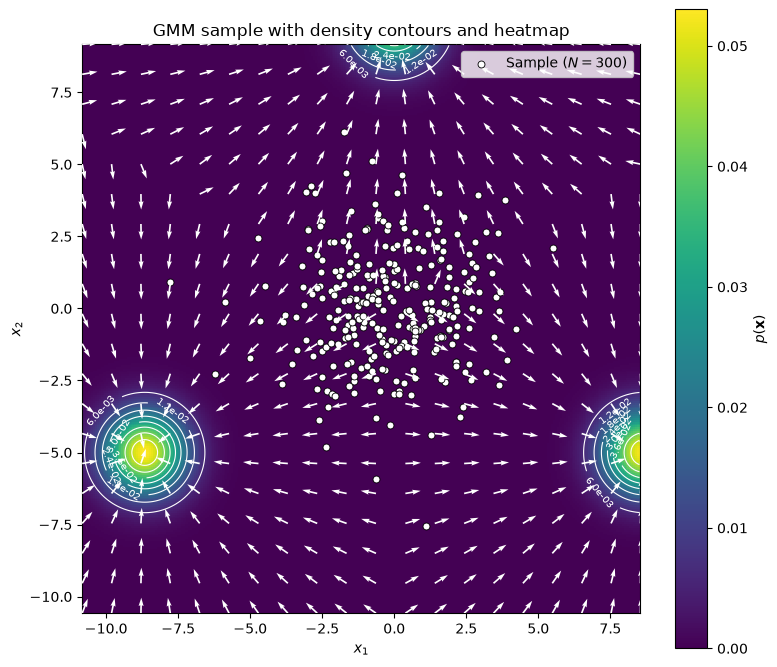

In [6]:
# Plot sample with density and score (force field)

fig, ax = gmm_plot_sample_with_density(samples, weights, means, covariances)

# Grid over the current axes limits
x_min, x_max = ax.get_xlim()
y_min, y_max = ax.get_ylim()

grid_res = 20
xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, grid_res),
    np.linspace(y_min, y_max, grid_res),
)
grid_points = np.stack([xx, yy], axis=-1)  # (grid_res, grid_res, 2)

# Score field on the grid
scores = gmm_score(grid_points, weights, means, covariances)  # (grid_res, grid_res, 2)
u, v = scores[..., 0], scores[..., 1]

# Normalize to unit vectors (direction only, since |s(x)| varies a lot)
magnitude = np.sqrt(u**2 + v**2)
magnitude = np.where(magnitude == 0, 1.0, magnitude)
u, v = u / magnitude, v / magnitude

# Overlay arrows
ax.quiver(xx, yy, u, v, color="white", alpha=1.0, zorder=4)

plt.show()  # only call this once, after all drawing is done

In [8]:
# [TO DO]: Rerun the code with the GMM  and comment the results

weights = np.array([0.3, 0.2, 0.3, 0.2])
means = np.array([[0.0, 0.0], [5.0, 4.0], [-4.0, 5.0], [8.0, -6.0]])
covariances = np.array(
    [
        [[1.0, 0.0], [0.0, 1.0]],
        [[1.5, -1.0], [-1.0, 0.8]],
        [[0.8, 0.4], [0.4, 1.2]],
        [[2.0, 1.4], [1.4, 1.0]],
    ]
)


### Questions
**[TODO]** Give short answers to the these question using markdown + latex:

1. The command `einsum`
    1. Explain what is the origin of the name of this command and what it means.
    2. Give some examples of the use of the command $einsum$ for tensor operations (for instance, to transpose a matrix, to multiply two matrices, and so on).
    3. Explain why is  useful in convolutional neural networks.
2. The score function
    1. Explain, using the Gibbs (aka Boltzmann) form of the pdf, why can the score be understood as a force field for a probability flow.
    2. Explain what is the advantage of using score-based methods to generate samples that methods that employ directly the pdf.
3. Langevin sampling
    1. Explain the meaning of "drift" and "diffusion" in the Langevin equation.
    2. What happens in ULA when $\eta$ is too small?
    3. What happens in ULA when $\eta$ is too large?
    4. And in ULA?



### Answers
**1. The command einsum**

**A.** The command ```einsum``` stands for "Einstein summation" since it was introduced by Albert Einstein in 1916 to simplify the writing of equations in physics. He realized that if an index variable appeared twice in a single term, it always meant those terms were being added together.
```einsum``` is a notational convention for simplifying expressions including summations of vectors, matrices, and general tensors. There are essentially three rules of Einstein summation notation, namely:

1. Repeated indices are implicitly summed over.

2. Each index can appear at most twice in any term.

3. Each term must contain identical non-repeated indices.

**B.** 
| Operation | Mathematical expression | `einsum` string |
|---|---|---|
| Transpose | $B_{ji}=A_{ij}$ | `"ij->ji"` |
| Matrix product | $C_{ij}=\sum_k A_{ik}B_{kj}$ | `"ik,kj->ij"` |
| Dot product | $\sum_i a_i b_i$ | `"i,i->"` |
| Trace | $\sum_i A_{ii}$ | `"ii->"` |
| Outer product | $C_{ij}=a_i b_j$ | `"i,j->ij"` |
| Quadratic form (Mahalanobis distance, used in this homework) | $d_k^2=\sum_{i,j}(x-\mu_k)_i\,(\Sigma_k^{-1})_{ij}\,(x-\mu_k)_j$ | `"...ki,kij,...kj->...k"` |

**C.**
The command ```einsum``` is useful in convolutional neural networks because it allows us to perform operations on tensors by explicitly specifying which dimensions should be multiplied and which ones should be summed.

For example, a convolution involves multiplying the input by the kernel and summing over the input channels and kernel dimensions:

$$
y_{b,o,h,w}=\sum_{c}\sum_{i,j} W_{o,c,i,j}\;x_{b,c,\,h+i,\,w+j}.
$$
If the input patches are extracted into an array $P_{b,c,i,j,h,w}$, the layer can be written in one line: `einsum("bcijhw,ocij->bohw", P, W)`.

This makes the operation more explicit and avoids using loops or manually applying operations such as reshape and transpose. It also makes it easier to work with the different dimensions of the input, such as the batch, channels and spatial dimensions.


### Summary and conclusions 
**[TODO]** Summary and conclusions of what I have learned using markdown + latex:
1. **Sampling from a GMM.** To sample from a mixture, the component of each sample is chosen first with a categorical distribution using the weights $\boldsymbol{\pi}$. Then a standard normal vector $\boldsymbol{\varepsilon}_n$ is drawn and transformed with the Cholesky factor of the chosen covariance, $\mathbf{x}_n=\boldsymbol{\mu}_{z_n}+\mathbf{L}_{z_n}\boldsymbol{\varepsilon}_n$. This works because $\mathbf{L}\boldsymbol{\varepsilon}$ has covariance $\mathbf{L}\mathbf{L}^{\top}=\boldsymbol{\Sigma}$. The good thing about this method is that the samples are IID.

2. **Using `einsum`.** The index string of `einsum` says which indices are summed (the ones that do not appear in the output) and which are kept. For the GMM this is very convenient, because the quadratic form $(\mathbf{x}-\boldsymbol{\mu}_k)^{\top}\boldsymbol{\Sigma}_k^{-1}(\mathbf{x}-\boldsymbol{\mu}_k)$ can be computed in one line, for all points and all components at the same time, with `"...ki,kij,...kj->...k"`. It also avoids explicit loops, so the code is shorter, faster and less prone to indexing mistakes.

3.
...
